In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería (notebooks/colecciones/<coleccion>/ -> ../../../src)
sys.path.append(os.path.abspath('../../../src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

In [2]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Considere el proyecto cuyo cuadro de prelaciones y estimaciones optimista, más probable y pesimista (en semanas) se adjunta. Suponga que la duración de cada actividad sigue una distribución Beta-PERT de parámetros $(a, m, b)$.

In [3]:
pregunta_1 = "1. Dibuje el grafo PERT, construya la matriz de caminos y calcule la duración del proyecto con las duraciones medias.  "
pregunta_2 = "2. Genere 10000 réplicas de las duraciones de las actividades y, con la matriz de caminos, obtenga la duración del proyecto en cada una. Calcule su media, desviación típica y percentiles 5, 50 y 95.  "
pregunta_3 = "3. Calcule la probabilidad de terminar en 23 semanas o menos y la duración que puede comprometerse con un 90% de probabilidad. Compare con la aproximación normal por el camino crítico y explique las diferencias.  "
pregunta_4 = "4. Calcule el índice de criticidad de cada ruta y de cada actividad. ¿Qué actividad no crítica convendría vigilar?  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Dibuje el grafo PERT, construya la matriz de caminos y calcule la duración del proyecto con las duraciones medias.  

2. Genere 10000 réplicas de las duraciones de las actividades y, con la matriz de caminos, obtenga la duración del proyecto en cada una. Calcule su media, desviación típica y percentiles 5, 50 y 95.  

3. Calcule la probabilidad de terminar en 23 semanas o menos y la duración que puede comprometerse con un 90% de probabilidad. Compare con la aproximación normal por el camino crítico y explique las diferencias.  

4. Calcule el índice de criticidad de cada ruta y de cada actividad. ¿Qué actividad no crítica convendría vigilar?  

In [4]:
#| tbl-cap: "Cuadro de datos del enunciado"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, a, m, b 
    ('A'     , '---'      , 5, 8, 11),
    ('B'     , '---'      , 3, 4, 5 ),
    ('C'     , '---'      , 5, 6, 7 ),
    ('D'     , 'B'        , 3, 4, 5 ),
    ('E'     , 'C'        , 1, 3, 5 ),
    ('F'     , 'D,E'      , 1, 6, 11),
    ('G'     , 'D'        , 3, 6, 9 ),
    ('H'     , 'D,E'      , 5, 7, 9 ),
    ('I'     , 'A,F,G,H'  , 4, 6, 8 ),
], columns=['activity', 'predecessor', 'a', 'm', 'b']).set_index('activity')
datos_enunciado

,predecessor,a,m,b
activity,,,,
A,---,5,8,11
B,---,3,4,5
C,---,5,6,7
D,B,3,4,5
E,C,1,3,5
F,"D,E",1,6,11
G,D,3,6,9
H,"D,E",5,7,9
I,"A,F,G,H",4,6,8


# Resolución

Con el método PERT la media de cada actividad es $(a + 4m + b)/6$ y su desviación típica se aproxima por $(b - a)/6$.

In [5]:
datos_proyecto = datos_enunciado.copy()
datos_proyecto['duration'] = datos_proyecto.eval('(a + 4 * m + b) / 6').round().astype(int)
datos_proyecto['standard_deviation'] = datos_proyecto.eval('(b - a) / 6')
datos_proyecto['variance'] = datos_proyecto['standard_deviation'] ** 2
datos_proyecto

,predecessor,a,m,b,duration,standard_deviation,variance
activity,,,,,,,
A,---,5,8,11,8,1.000000,1.000000
B,---,3,4,5,4,0.333333,0.111111
C,---,5,6,7,6,0.333333,0.111111
D,B,3,4,5,4,0.333333,0.111111
E,C,1,3,5,3,0.666667,0.444444
F,"D,E",1,6,11,6,1.666667,2.777778
G,D,3,6,9,6,1.000000,1.000000
H,"D,E",5,7,9,7,0.666667,0.444444
I,"A,F,G,H",4,6,8,6,0.666667,0.444444


In [6]:
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()

## Apartado 1

In [7]:
display(Markdown(pregunta_1))

1. Dibuje el grafo PERT, construya la matriz de caminos y calcule la duración del proyecto con las duraciones medias.  

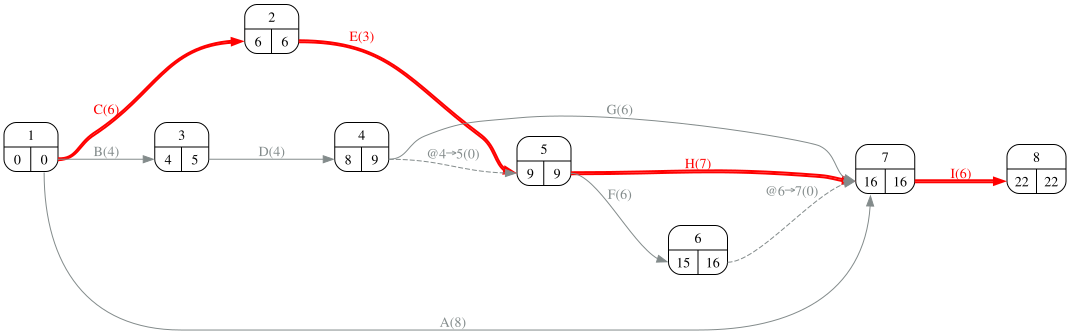

In [8]:
#| fig-cap: "Grafo PERT con las duraciones medias"
#| label: fig-pert
proyecto.pert(durations=datos_proyecto['duration'], ranksep=1)

In [9]:
#| tbl-cap: "Matriz de caminos"
#| label: tbl-matrizCaminos
path_matrix = proyecto.path_matrix(dummies=False)
proyecto.display_path_matrix(dummies=False)

,A,B,C,D,E,F,G,H,I
Route_1,1,0,0,0,0,0,0,0,1
Route_2,0,1,0,1,0,1,0,0,1
Route_3,0,1,0,1,0,0,1,0,1
Route_4,0,1,0,1,0,0,0,1,1
Route_5,0,0,1,0,1,1,0,0,1
Route_6,0,0,1,0,1,0,0,1,1


In [10]:
duraciones = datos_proyecto['duration'][path_matrix.columns]
duraciones_rutas_medias = path_matrix @ duraciones
duracion_media = int(duraciones_rutas_medias.max())
ruta_critica = duraciones_rutas_medias.idxmax()
desviacion_proyecto, varianza_rutas = proyecto.standard_deviation(durations=datos_proyecto['duration'], variances=datos_proyecto['variance'])
pd.concat([duraciones_rutas_medias.rename('duración media'),
           (path_matrix @ datos_proyecto['variance'][path_matrix.columns]).rename('varianza')], axis=1)

,duración media,varianza
Route_1,14,1.444444
Route_2,20,3.444444
Route_3,20,1.666667
Route_4,21,1.111111
Route_5,21,3.777778
Route_6,22,1.444444


In [11]:
Markdown(f'Con las duraciones medias el proyecto dura {duracion_media} semanas; la ruta crítica es {ruta_critica} y su desviación típica {desviacion_proyecto:.3f}.')

Con las duraciones medias el proyecto dura 22 semanas; la ruta crítica es Route_6 y su desviación típica 1.202.

## Apartado 2

In [12]:
display(Markdown(pregunta_2))

2. Genere 10000 réplicas de las duraciones de las actividades y, con la matriz de caminos, obtenga la duración del proyecto en cada una. Calcule su media, desviación típica y percentiles 5, 50 y 95.  

La Beta-PERT de parámetros $(a, m, b)$ es $X = a + (b - a)\,Y$ con $Y \sim \mathrm{Beta}(\alpha, \beta)$, $\alpha = 1 + 4\frac{m-a}{b-a}$ y $\beta = 1 + 4\frac{b-m}{b-a}$; su media es exactamente $(a+4m+b)/6$.

In [13]:
N = 10000
rng = np.random.default_rng(557)
def muestras_beta_pert(a, m, b, size):
    if b == a:
        return np.full(size, float(a))
    alfa = 1 + 4 * (m - a) / (b - a)
    beta = 1 + 4 * (b - m) / (b - a)
    return a + (b - a) * rng.beta(alfa, beta, size)
duraciones_mc = pd.DataFrame({act: muestras_beta_pert(fila['a'], fila['m'], fila['b'], N)
                              for act, fila in datos_proyecto.iterrows()})
duraciones_mc = duraciones_mc[path_matrix.columns]

In [14]:
#| tbl-cap: "Medias y desviaciones típicas muestrales frente a las teóricas"
#| label: tbl-comprobacionMuestras
pd.DataFrame({'media teórica': datos_proyecto['duration'], 'media muestral': duraciones_mc.mean(),
              'σ teórica': datos_proyecto['standard_deviation'], 'σ muestral': duraciones_mc.std()}).round(2).T

,A,B,C,D,E,F,G,H,I
media teórica,8.00,4.00,6.00,4.00,3.00,6.00,6.00,7.00,6.00
media muestral,8.00,4.00,5.99,4.00,2.99,6.02,6.01,6.99,6.00
σ teórica,1.00,0.33,0.33,0.33,0.67,1.67,1.00,0.67,0.67
σ muestral,1.14,0.38,0.38,0.38,0.75,1.90,1.14,0.75,0.76


Las medias muestrales coinciden con las teóricas. Las desviaciones típicas salen algo mayores que $(b-a)/6$: esa fórmula es una aproximación; la desviación exacta de la Beta-PERT simétrica es $(b-a)/\sqrt{28} \approx (b-a)/5.3$.

La duración de cada ruta en cada réplica es el producto de las duraciones por la traspuesta de la matriz de caminos; la del proyecto, el máximo por filas.

In [15]:
duraciones_rutas_mc = duraciones_mc @ path_matrix.T
duracion_proyecto_mc = duraciones_rutas_mc.max(axis='columns')
pd.concat([duraciones_rutas_mc, duracion_proyecto_mc.rename('Proyecto')], axis=1).head().round(2)

,Route_1,Route_2,Route_3,Route_4,Route_5,Route_6,Proyecto
0,16.17,18.96,18.70,20.68,21.32,23.03,23.03
1,12.10,19.41,19.33,22.03,18.54,21.16,22.03
2,12.98,20.13,19.59,20.86,20.74,21.46,21.46
3,14.06,15.05,20.12,20.58,16.88,22.42,22.42
4,14.23,23.82,22.05,22.55,23.87,22.61,23.87


In [16]:
#| tbl-cap: "Descriptores de la duración simulada del proyecto"
#| label: tbl-descriptores
duracion_proyecto_mc.describe(percentiles=[0.05, 0.5, 0.95]).round(2).to_frame('Duración del proyecto').T

,count,mean,std,min,5%,50%,95%,max
Duración del proyecto,10000.0,22.54,1.38,17.79,20.37,22.48,24.89,27.83


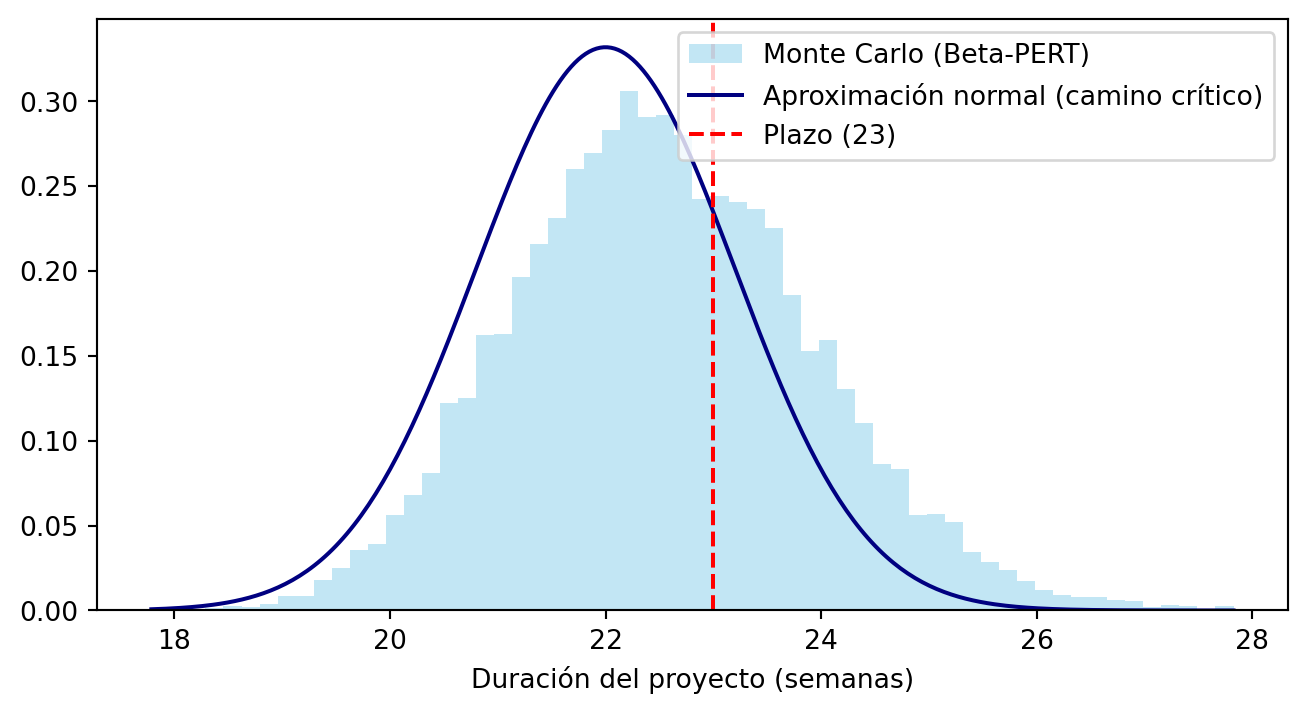

In [17]:
#| fig-cap: "Distribución simulada de la duración frente a la aproximación normal"
#| label: fig-histograma
from matplotlib import pyplot as plt
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(duracion_proyecto_mc, bins=60, density=True, alpha=0.5, color='skyblue', label='Monte Carlo (Beta-PERT)')
x = np.linspace(duracion_proyecto_mc.min(), duracion_proyecto_mc.max(), 300)
ax.plot(x, norm.pdf(x, duracion_media, desviacion_proyecto), color='navy', label='Aproximación normal (camino crítico)')
ax.axvline(23, color='red', linestyle='--', label='Plazo (23)')
ax.set_xlabel('Duración del proyecto (semanas)'); ax.legend(); plt.show()

## Apartado 3

In [18]:
display(Markdown(pregunta_3))

3. Calcule la probabilidad de terminar en 23 semanas o menos y la duración que puede comprometerse con un 90% de probabilidad. Compare con la aproximación normal por el camino crítico y explique las diferencias.  

In [19]:
plazo, probabilidad_objetivo = 23, 0.9
p_mc = float((duracion_proyecto_mc <= plazo).mean())
t_mc = float(duracion_proyecto_mc.quantile(probabilidad_objetivo))
p_normal = float(norm.cdf((plazo - duracion_media) / desviacion_proyecto))
t_normal = float(duracion_media + norm.ppf(probabilidad_objetivo) * desviacion_proyecto)
pd.DataFrame({'Aproximación normal': [duracion_media, desviacion_proyecto, p_normal * 100, t_normal],
              'Monte Carlo': [duracion_proyecto_mc.mean(), duracion_proyecto_mc.std(), p_mc * 100, t_mc]},
             index=['Duración media', 'Desviación típica', f'P(T ≤ {plazo}) (%)', f'Duración para {int(probabilidad_objetivo*100)}%']).round(2)

,Aproximación normal,Monte Carlo
Duración media,22.00,22.54
Desviación típica,1.20,1.38
P(T ≤ 23) (%),79.73,64.10
Duración para 90%,23.54,24.33


La aproximación normal sólo mira la ruta crítica. En cada réplica, sin embargo, la duración del proyecto es el máximo de todas las rutas, y el máximo de varias variables aleatorias tiene una media mayor que cualquiera de ellas: las rutas casi críticas empujan la duración hacia arriba (*sesgo de fusión*). Por eso Monte Carlo da una duración media algo mayor y una probabilidad de cumplir el plazo algo menor: el método PERT clásico es optimista. La desviación típica simulada suele ser menor, porque cuando una ruta sale corta otra ocupa su lugar y la cola izquierda se recorta.

## Apartado 4

In [20]:
display(Markdown(pregunta_4))

4. Calcule el índice de criticidad de cada ruta y de cada actividad. ¿Qué actividad no crítica convendría vigilar?  

El índice de criticidad de una ruta es la fracción de réplicas en que es la más larga; el de una actividad, la fracción de réplicas en que pertenece a la ruta más larga.

In [21]:
#| tbl-cap: "Índice de criticidad de las rutas"
#| label: tbl-criticidadRutas
ruta_critica_mc = duraciones_rutas_mc.idxmax(axis='columns')
criticidad_rutas = (ruta_critica_mc.value_counts(normalize=True) * 100).reindex(path_matrix.index, fill_value=0.0)
actividades_ruta = path_matrix.apply(lambda fila: ' - '.join(fila.index[fila == 1]), axis=1)
pd.DataFrame({'actividades': actividades_ruta, 'duración media': duraciones_rutas_medias,
              'criticidad (%)': criticidad_rutas}).sort_values('criticidad (%)', ascending=False).round(1)

,actividades,duración media,criticidad (%)
Route_6,C - E - H - I,22,52.4
Route_5,C - E - F - I,21,26.6
Route_4,B - D - H - I,21,8.6
Route_3,B - D - G - I,20,7.3
Route_2,B - D - F - I,20,5.1
Route_1,A - I,14,0.0


In [22]:
#| tbl-cap: "Índice de criticidad de las actividades frente a su holgura total"
#| label: tbl-criticidadActividades
criticidad_actividades = path_matrix.loc[ruta_critica_mc].mean() * 100
calendario = proyecto.calendar(datos_proyecto['duration'])
pd.DataFrame({'holgura total': calendario['H_total'], 'criticidad (%)': criticidad_actividades}).round(1).T

,A,B,C,D,E,F,G,H,I
holgura total,8.0,1.0,0.0,1.0,0.0,1.0,2.0,0.0,0.0
criticidad (%),0.0,21.0,79.0,21.0,79.0,31.7,7.3,61.0,100.0


La librería hace el mismo cálculo de forma vectorizada: la sensibilidad empírica media de `monte_carlo` es precisamente el índice de criticidad de cada actividad.

In [23]:
resultado = proyecto.monte_carlo({act: ('pert', fila['a'], fila['m'], fila['b']) for act, fila in datos_proyecto.iterrows()}, n_samples=N, seed=557)
display(resultado.summary().round(2))
(resultado.sensitivity_mean * 100).round(1).to_frame('criticidad (%) según monte_carlo').T

,mean,std,q05,q50,q95,min,max
τ,22.41,1.24,20.48,22.35,24.51,18.33,27.99


,I,E,C,H,F,D,B,G,A
criticidad (%) según monte_carlo,100.0,83.7,83.7,66.5,28.2,16.3,16.3,5.3,0.0


In [24]:
vigilar = criticidad_actividades[calendario['H_total'] > 0].sort_values(ascending=False)
Markdown(f'''La actividad no crítica con mayor índice de criticidad es **{vigilar.index[0]}** ({vigilar.iloc[0]:.1f} % de las réplicas en la ruta más larga, con holgura {int(calendario.loc[vigilar.index[0], "H_total"])}). El análisis determinista la da por holgada, pero un retraso pequeño la convierte en crítica: es la que conviene vigilar.''')

La actividad no crítica con mayor índice de criticidad es **F** (31.7 % de las réplicas en la ruta más larga, con holgura 1). El análisis determinista la da por holgada, pero un retraso pequeño la convierte en crítica: es la que conviene vigilar.